In [5]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Наложение и удаление шума

In [6]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

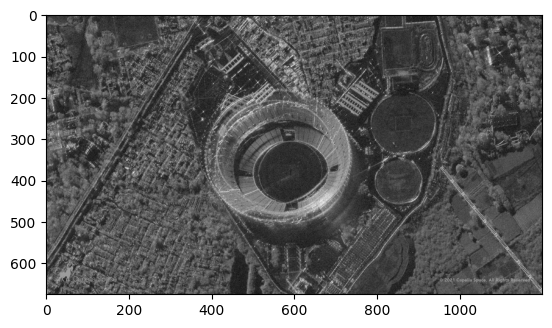

In [7]:
plt.imshow(image_gray, cmap="gray")

In [8]:
# Gaussian noise
mean = 0
stddev = 100
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)

array([[  0,  16,   0, ..., 111,   0,  80],
       [  1, 104,  68, ...,   0, 103,   0],
       [  0,   0,  51, ...,   0,   0, 145],
       ...,
       [  0,   0,  39, ..., 255,   0,  15],
       [  0,  34,   0, ...,   0,   5, 135],
       [160, 204,   0, ...,  21,   0, 109]], dtype=uint8)

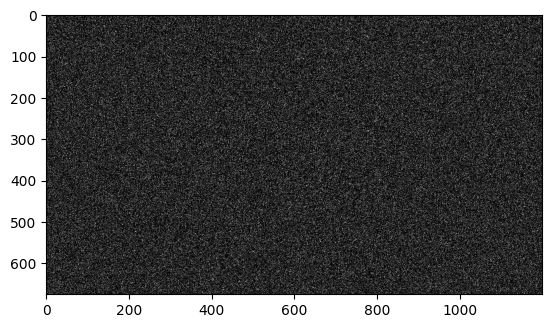

In [9]:
plt.imshow(noise_gauss, cmap="gray")

In [10]:
# Salt and pepper
noise =  np.random.randint(0, 101, size = (image_gray.shape[0], image_gray.shape[1]), dtype=int)
zeros_pixel = np.where(noise == 0)
ones_pixel = np.where(noise == 100)

In [11]:
bg_image = np.ones(image_gray.shape, np.uint8) * 128

In [12]:
bg_image[zeros_pixel] = 0
bg_image[ones_pixel] = 255

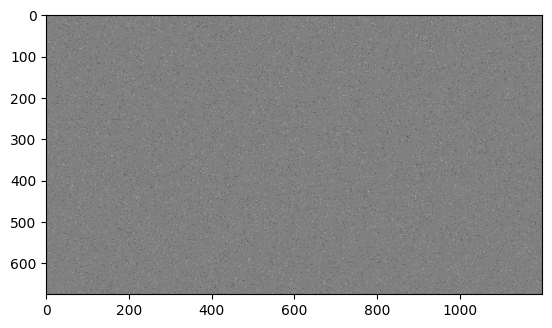

In [13]:
plt.imshow(bg_image, cmap="gray")

In [14]:
image_noise_gauss = cv2.add(image_gray,noise_gauss)

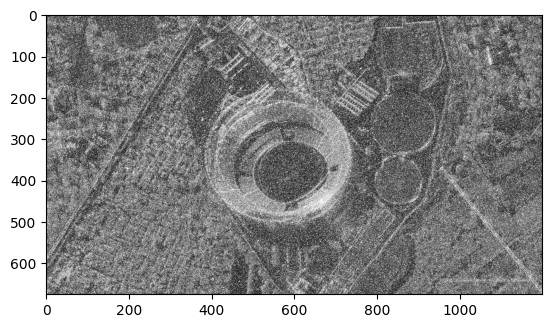

In [15]:
plt.imshow(image_noise_gauss, cmap="gray")

In [16]:
from skimage.metrics import structural_similarity, mean_squared_error
mse_gauss = mean_squared_error(image_gray, image_noise_gauss)
(ssim, diff) = structural_similarity(image_gray, image_noise_gauss, full=True)
print(mse_gauss, ssim)

4230.673058024691 0.1869926680003536


In [17]:
image_gauss_median = cv2.medianBlur(image_noise_gauss, 3)

In [18]:
mse_gauss_median = mean_squared_error(image_gray, image_gauss_median)
(ssim_gauss_median, diff) = structural_similarity(image_gray,  image_gauss_median, full=True)

In [19]:
print(mse_gauss_median, ssim_gauss_median)

1038.0453432098766 0.4282430571563417


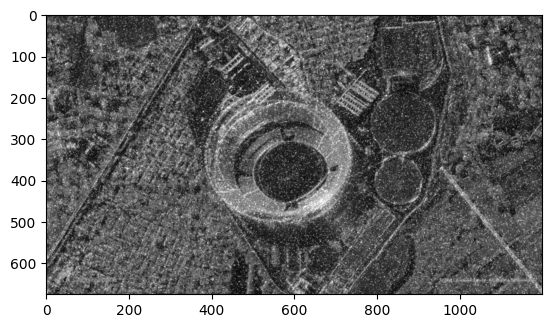

In [20]:
plt.imshow(image_gauss_median, cmap="gray")

In [21]:
import copy

image_sp = copy.deepcopy(image_gray)

image_sp[zeros_pixel] = 0
image_sp[ones_pixel] = 255

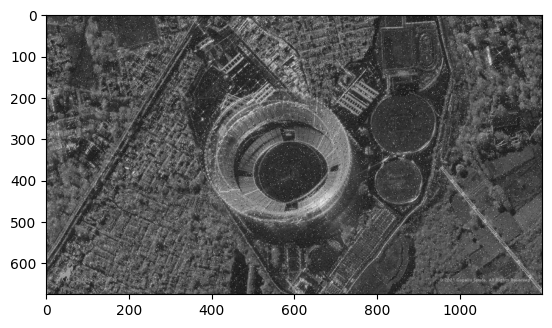

In [22]:
plt.imshow(image_sp, cmap="gray")

In [23]:
mse_sp = mean_squared_error(image_gray, image_sp)
(ssim_sp, diff) = structural_similarity(image_gray, image_sp, full=True)
print(mse_sp, ssim_sp)

387.54226419753087 0.7207913549380005


In [24]:
image_sp_median = cv2.medianBlur(image_sp, 3)

In [25]:
mse_sp_median = mean_squared_error(image_gray, image_sp_median)
(ssim_sp_median, diff) = structural_similarity(image_gray, image_sp_median, full=True)
print(mse_sp_median, ssim_sp_median)

95.80562345679013 0.816074572475447


# Другие типы фильтров

In [26]:
image_gauss_gauss = cv2.GaussianBlur(image_noise_gauss,(5,5),0)

In [27]:
image_gauss_bilat = cv2.bilateralFilter(image_noise_gauss,9,75,75)

In [28]:
image_gauss_nlm = cv2.fastNlMeansDenoising(image_noise_gauss, h = 20)

In [29]:
import math

def geom(a):
    prod = 1
    for i in range(a.shape[0]):
        prod1 = 1
        for j in range(a.shape[1]):
            prod1 *= a[i,j]
        prod1 = math.pow(prod1, 1.0/9.0)
        prod *= prod1
    return prod

def proc(img, filter):
    img_res = copy.deepcopy(img)
    for i in range(0,img.shape[0] -2):
        for j in range(0,img.shape[1] -2):
            img_res[i:i+3, j:j+3] = filter(img[i:i+3, j:j+3])
    return img_res

res = proc(image_noise_gauss, geom)


/tmp/ipykernel_783/164976186.py:8: RuntimeWarning: overflow encountered in scalar multiply
  prod1 *= a[i,j]


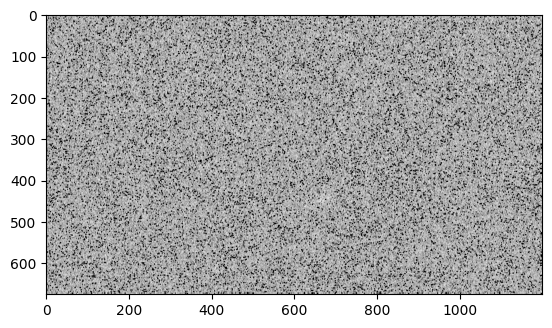

In [30]:
plt.imshow(res, cmap="gray")

In [31]:
mse_geom = mean_squared_error(image_gray, res)
(ssim_geom, diff) = structural_similarity(image_gray, res, full=True)
print(mse_geom, ssim_geom)

6551.976648148148 0.02746126776511091



# 2D свертка

In [32]:
# averaging filter
kernel_5 = np.ones((5,5),np.float32)/25
image_k5 = cv2.filter2D(image_gray,-1,kernel_5)
# blured_image = cv2.blur(img,(5,5))
image_b5 = cv2.blur(image_gray,(5,5))

In [33]:
mse_kb = mean_squared_error(image_k5, image_b5)
(ssim_kb, diff) = structural_similarity(image_k5, image_b5, full=True)
print(mse_kb, ssim_kb)

0.0 1.0


In [34]:
# Laplasian
kernel_lapl = np.array([[0,-10,0],
                        [-10,40,-10],
                        [0,-10,0]], np.float32)

In [35]:
image_lapl = cv2.filter2D(image_gray,-1,kernel_lapl)

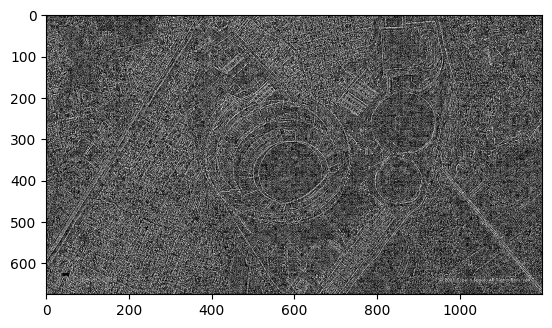

In [36]:
plt.imshow(image_lapl, cmap="gray")

In [37]:
# ДЗ 2
# Зашумить изображение при помощи шума гаусса, постоянного шума.
# Протестировать медианный фильтр, фильтр гаусса, билатериальный фильтр, фильтр нелокальных средних с различными параметрами.
# Выяснить, какой фильтр показал лучший результат фильтрации шума.

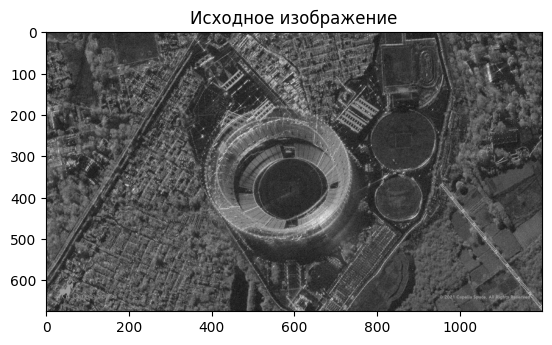

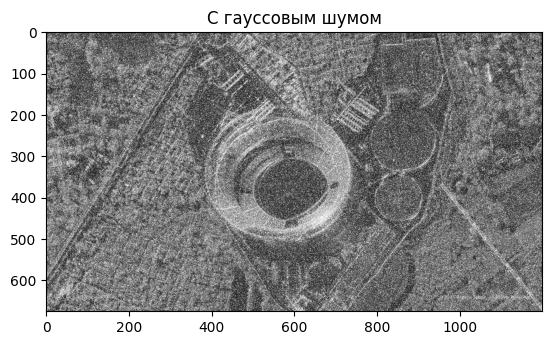

Гауссов шум: MSE = 4226.025272839506  SSIM = 0.18728917567733971


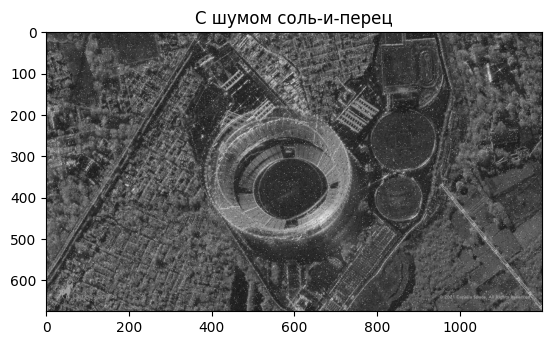

Соль-и-перец: MSE = 382.88606419753086  SSIM = 0.7226469664240426


In [38]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap="gray")
plt.title('Исходное изображение')
plt.show()

mean = 0
stddev = 100
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)

image_noise_gauss = cv2.add(image_gray, noise_gauss)

plt.imshow(image_noise_gauss, cmap="gray")
plt.title('С гауссовым шумом')
plt.show()

mse_gauss = mean_squared_error(image_gray, image_noise_gauss)
(ssim_gauss, diff) = structural_similarity(image_gray, image_noise_gauss, full=True)
print('Гауссов шум: MSE =', mse_gauss, ' SSIM =', ssim_gauss)

noise = np.random.randint(0, 101, size=(image_gray.shape[0], image_gray.shape[1]), dtype=int)
zeros_pixel = np.where(noise == 0)
ones_pixel = np.where(noise == 100)

image_sp = copy.deepcopy(image_gray)
image_sp[zeros_pixel] = 0
image_sp[ones_pixel] = 255

plt.imshow(image_sp, cmap="gray")
plt.title('С шумом Соль и перец')
plt.show()

mse_sp = mean_squared_error(image_gray, image_sp)
(ssim_sp, diff) = structural_similarity(image_gray, image_sp, full=True)
print('Соль и перец: MSE =', mse_sp, ' SSIM =', ssim_sp)

Медианный, гауссов шум: MSE = 1035.5800814814816  SSIM = 0.4294396202069238
Медианный, соль-и-перец: MSE = 95.67595802469135  SSIM = 0.8161853448541997


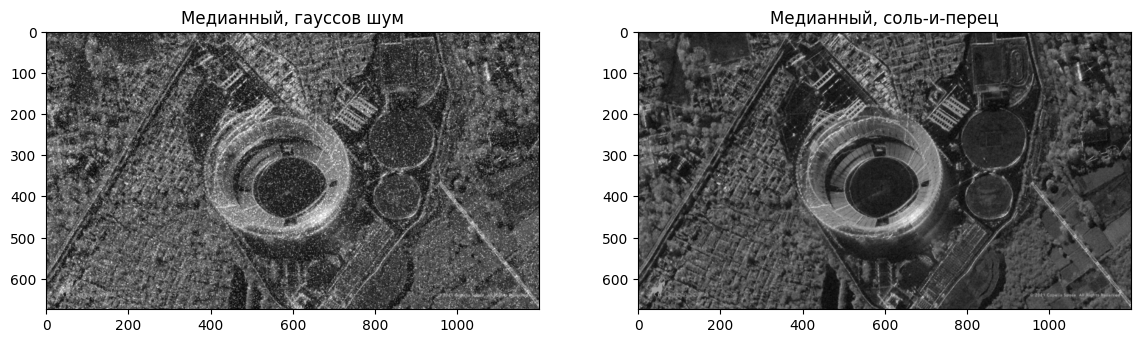

Гаусс(3x3), гауссов шум : MSE = 1900.5135469135803  SSIM = 0.44085446720869026
Гаусс(5x5), гауссов шум : MSE = 1761.8077950617285  SSIM = 0.4866425055601689
Гаусс(3x3), соль-и-перец : MSE = 120.33346666666667  SSIM = 0.7847746796724709
Гаусс(5x5), соль-и-перец : MSE = 142.01606543209877  SSIM = 0.7354950887042732


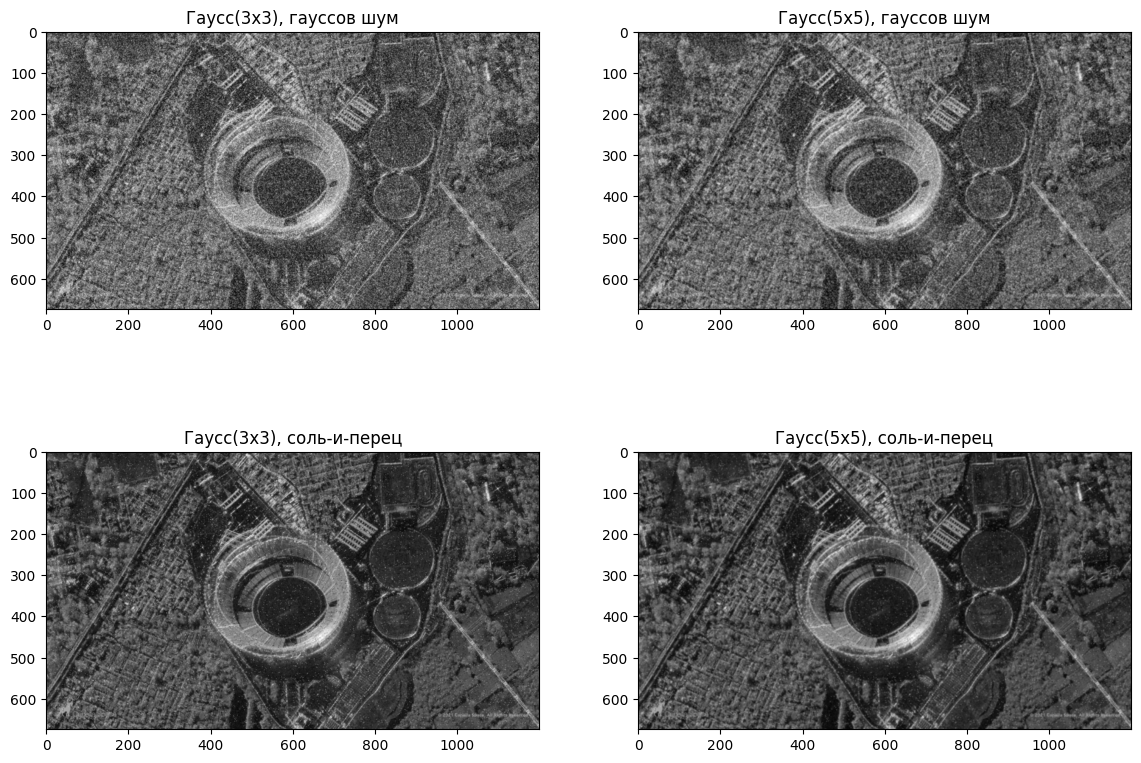

In [39]:
image_gauss_median = cv2.medianBlur(image_noise_gauss, 3)
image_sp_median = cv2.medianBlur(image_sp, 3)

mse_gauss_median = mean_squared_error(image_gray, image_gauss_median)
(ssim_gauss_median, diff) = structural_similarity(image_gray, image_gauss_median, full=True)
print('Медианный, гауссов шум: MSE =', mse_gauss_median, ' SSIM =', ssim_gauss_median)

mse_sp_median = mean_squared_error(image_gray, image_sp_median)
(ssim_sp_median, diff) = structural_similarity(image_gray, image_sp_median, full=True)
print('Медианный, Соль и перец: MSE =', mse_sp_median, ' SSIM =', ssim_sp_median)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(image_gauss_median, cmap="gray"); ax[0].set_title('Медианный, гауссов шум')
ax[1].imshow(image_sp_median, cmap="gray"); ax[1].set_title('Медианный, Соль и перец')
plt.show()

image_gauss_gauss3 = cv2.GaussianBlur(image_noise_gauss, (3,3), 0)
image_gauss_gauss5 = cv2.GaussianBlur(image_noise_gauss, (5,5), 0)
image_sp_gauss3 = cv2.GaussianBlur(image_sp, (3,3), 0)
image_sp_gauss5 = cv2.GaussianBlur(image_sp, (5,5), 0)

for name, im in [('Гаусс(3x3), гауссов шум', image_gauss_gauss3),
                  ('Гаусс(5x5), гауссов шум', image_gauss_gauss5),
                  ('Гаусс(3x3), Соль и перец', image_sp_gauss3),
                  ('Гаусс(5x5), Соль и перец', image_sp_gauss5)]:
    mse = mean_squared_error(image_gray, im)
    (ssim, diff) = structural_similarity(image_gray, im, full=True)
    print(name, ': MSE =', mse, ' SSIM =', ssim)

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0,0].imshow(image_gauss_gauss3, cmap="gray"); ax[0,0].set_title('Гаусс(3x3), гауссов шум')
ax[0,1].imshow(image_gauss_gauss5, cmap="gray"); ax[0,1].set_title('Гаусс(5x5), гауссов шум')
ax[1,0].imshow(image_sp_gauss3, cmap="gray"); ax[1,0].set_title('Гаусс(3x3), Соль и перец')
ax[1,1].imshow(image_sp_gauss5, cmap="gray"); ax[1,1].set_title('Гаусс(5x5), Соль и перец')
plt.show()

Билатеральный(75,75), гауссов шум : MSE = 1835.839639506173  SSIM = 0.31506140403628613
Билатеральный(25,25), гауссов шум : MSE = 3779.118972839506  SSIM = 0.1817579786316534
Билатеральный(75,75), соль-и-перец : MSE = 264.3485765432099  SSIM = 0.5212241269608675
Билатеральный(25,25), соль-и-перец : MSE = 427.32162098765434  SSIM = 0.5796731317508441


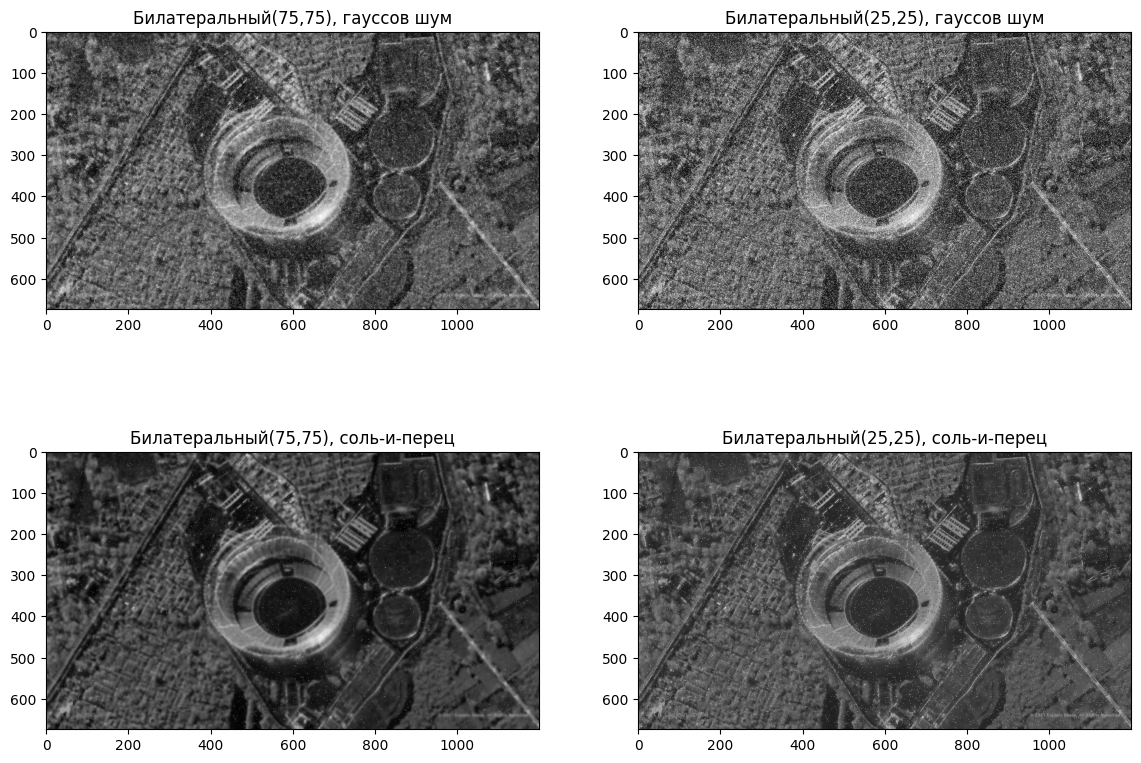

NLM(h=10), гауссов шум : MSE = 4226.022839506173  SSIM = 0.18729040059573604
NLM(h=20), гауссов шум : MSE = 4221.6409370370375  SSIM = 0.18772865263575678
NLM(h=10), соль-и-перец : MSE = 388.9147987654321  SSIM = 0.669435134884147
NLM(h=20), соль-и-перец : MSE = 217.0392012345679  SSIM = 0.5929603864448948


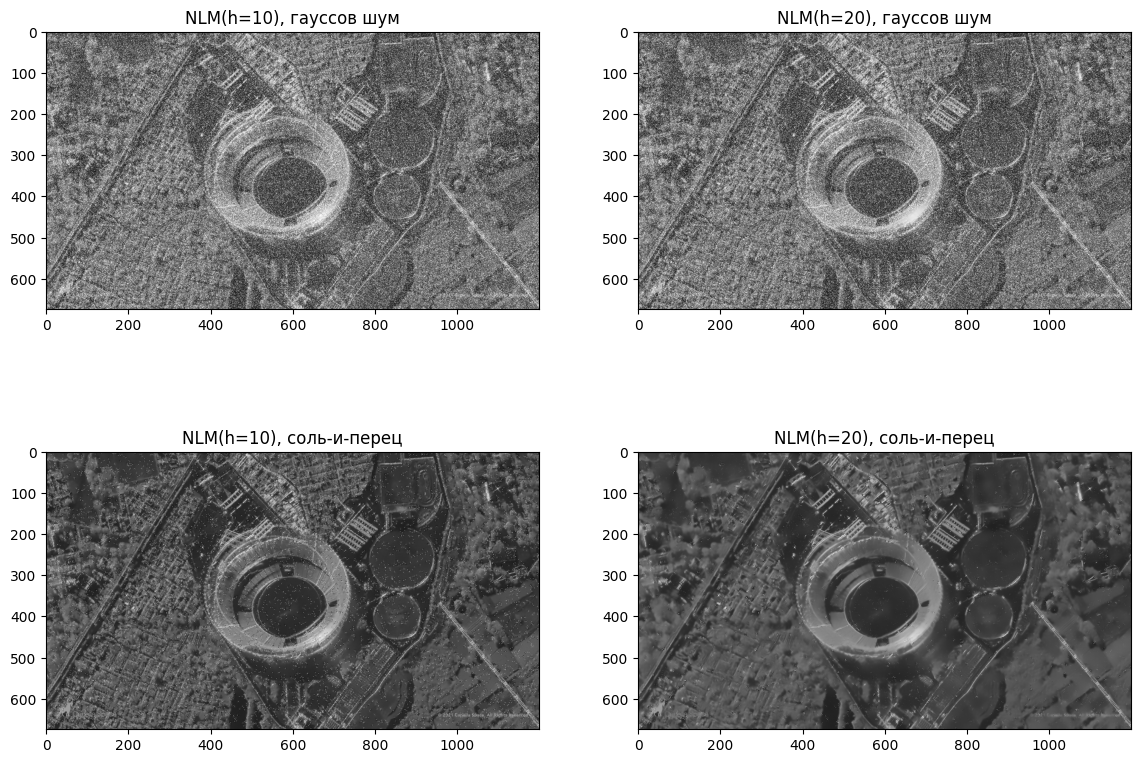

In [40]:
image_gauss_bilat1 = cv2.bilateralFilter(image_noise_gauss, 9, 75, 75)
image_gauss_bilat2 = cv2.bilateralFilter(image_noise_gauss, 9, 25, 25)
image_sp_bilat1 = cv2.bilateralFilter(image_sp, 9, 75, 75)
image_sp_bilat2 = cv2.bilateralFilter(image_sp, 9, 25, 25)

for name, im in [('Билатеральный(75,75), гауссов шум', image_gauss_bilat1),
                  ('Билатеральный(25,25), гауссов шум', image_gauss_bilat2),
                  ('Билатеральный(75,75), Соль и перец', image_sp_bilat1),
                  ('Билатеральный(25,25), Соль и перец', image_sp_bilat2)]:
    mse = mean_squared_error(image_gray, im)
    (ssim, diff) = structural_similarity(image_gray, im, full=True)
    print(name, ': MSE =', mse, ' SSIM =', ssim)

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0,0].imshow(image_gauss_bilat1, cmap="gray"); ax[0,0].set_title('Билатеральный(75,75), гауссов шум')
ax[0,1].imshow(image_gauss_bilat2, cmap="gray"); ax[0,1].set_title('Билатеральный(25,25), гауссов шум')
ax[1,0].imshow(image_sp_bilat1, cmap="gray"); ax[1,0].set_title('Билатеральный(75,75), Соль и перец')
ax[1,1].imshow(image_sp_bilat2, cmap="gray"); ax[1,1].set_title('Билатеральный(25,25), Соль и перец')
plt.show()

image_gauss_nlm10 = cv2.fastNlMeansDenoising(image_noise_gauss, h=10)
image_gauss_nlm20 = cv2.fastNlMeansDenoising(image_noise_gauss, h=20)
image_sp_nlm10 = cv2.fastNlMeansDenoising(image_sp, h=10)
image_sp_nlm20 = cv2.fastNlMeansDenoising(image_sp, h=20)

for name, im in [('NLM(h=10), гауссов шум', image_gauss_nlm10),
                  ('NLM(h=20), гауссов шум', image_gauss_nlm20),
                  ('NLM(h=10), Соль и перец', image_sp_nlm10),
                  ('NLM(h=20), Соль и перец', image_sp_nlm20)]:
    mse = mean_squared_error(image_gray, im)
    (ssim, diff) = structural_similarity(image_gray, im, full=True)
    print(name, ': MSE =', mse, ' SSIM =', ssim)

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0,0].imshow(image_gauss_nlm10, cmap="gray"); ax[0,0].set_title('NLM(h=10), гауссов шум')
ax[0,1].imshow(image_gauss_nlm20, cmap="gray"); ax[0,1].set_title('NLM(h=20), гауссов шум')
ax[1,0].imshow(image_sp_nlm10, cmap="gray"); ax[1,0].set_title('NLM(h=10), Соль и перец')
ax[1,1].imshow(image_sp_nlm20, cmap="gray"); ax[1,1].set_title('NLM(h=20), Соль и перец')
plt.show()

NLM(h=60), гауссов шум : MSE = 1799.2457975308641  SSIM = 0.329278586147535
NLM(h=100), гауссов шум : MSE = 1886.2667839506173  SSIM = 0.2702272861533144


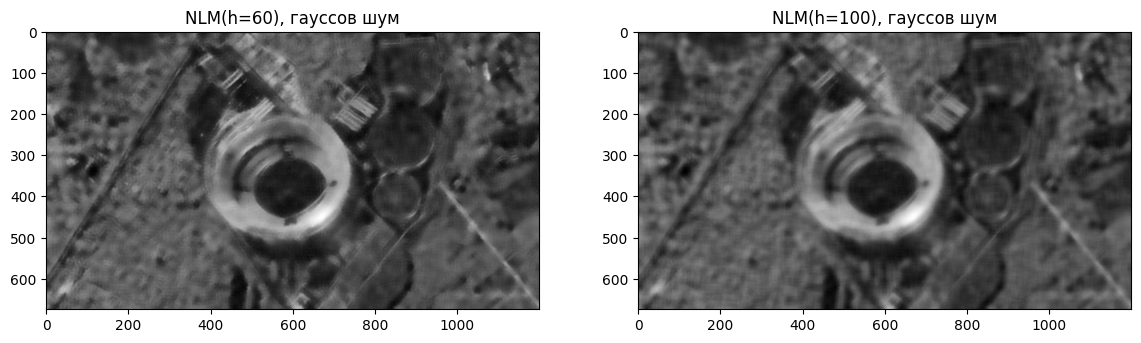

In [41]:
image_gauss_nlm60 = cv2.fastNlMeansDenoising(image_noise_gauss, h=60)
image_gauss_nlm100 = cv2.fastNlMeansDenoising(image_noise_gauss, h=100)

for name, im in [('NLM(h=60), гауссов шум', image_gauss_nlm60),
                  ('NLM(h=100), гауссов шум', image_gauss_nlm100)]:
    mse = mean_squared_error(image_gray, im)
    (ssim, diff) = structural_similarity(image_gray, im, full=True)
    print(name, ': MSE =', mse, ' SSIM =', ssim)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(image_gauss_nlm60, cmap="gray"); ax[0].set_title('NLM(h=60), гауссов шум')
ax[1].imshow(image_gauss_nlm100, cmap="gray"); ax[1].set_title('NLM(h=100), гауссов шум')
plt.show()

In [43]:
import pandas as pd

results = [
    ('Без фильтра', 'Гауссов шум', '-', 4226.03, 0.1873),
    ('Без фильтра', 'Соль и перец', '-', 382.89, 0.7226),
    ('Медианный', 'Гауссов шум', '3x3', 1035.58, 0.4294),
    ('Медианный', 'Соль и перец', '3x3', 95.68, 0.8162),
    ('Гаусс', 'Гауссов шум', '3x3', 1900.51, 0.4409),
    ('Гаусс', 'Гауссов шум', '5x5', 1761.81, 0.4866),
    ('Гаусс', 'Соль и перец', '3x3', 120.33, 0.7848),
    ('Гаусс', 'Соль и перец', '5x5', 142.02, 0.7355),
    ('Билатеральный', 'Гауссов шум', 'sigma=75', 1835.84, 0.3151),
    ('Билатеральный', 'Гауссов шум', 'sigma=25', 3779.12, 0.1818),
    ('Билатеральный', 'Соль и перец', 'sigma=75', 264.35, 0.5212),
    ('Билатеральный', 'Соль и перец', 'sigma=25', 427.32, 0.5797),
    ('NLM', 'Гауссов шум', 'h=10', 4226.02, 0.1873),
    ('NLM', 'Гауссов шум', 'h=20', 4221.64, 0.1877),
    ('NLM', 'Гауссов шум', 'h=60', 1799.25, 0.3293),
    ('NLM', 'Гауссов шум', 'h=100', 1886.27, 0.2702),
    ('NLM', 'Соль и перец', 'h=10', 388.91, 0.6694),
    ('NLM', 'Соль и перец', 'h=20', 217.04, 0.5930),
]

df = pd.DataFrame(results, columns=['Фильтр', 'Шум', 'Параметры', 'MSE', 'SSIM'])

print('=== Гауссов шум, по возрастанию MSE ===')
print(df[df['Шум'] == 'Гауссов шум'].sort_values('MSE').to_string(index=False))
print()
print('=== Соль и перец, по возрастанию MSE ===')
print(df[df['Шум'] == 'Соль и перец'].sort_values('MSE').to_string(index=False))

=== Гауссов шум, по возрастанию MSE ===
       Фильтр         Шум Параметры     MSE   SSIM
    Медианный Гауссов шум       3x3 1035.58 0.4294
        Гаусс Гауссов шум       5x5 1761.81 0.4866
          NLM Гауссов шум      h=60 1799.25 0.3293
Билатеральный Гауссов шум  sigma=75 1835.84 0.3151
          NLM Гауссов шум     h=100 1886.27 0.2702
        Гаусс Гауссов шум       3x3 1900.51 0.4409
Билатеральный Гауссов шум  sigma=25 3779.12 0.1818
          NLM Гауссов шум      h=20 4221.64 0.1877
          NLM Гауссов шум      h=10 4226.02 0.1873
  Без фильтра Гауссов шум         - 4226.03 0.1873

=== Соль-и-перец, по возрастанию MSE ===
Empty DataFrame
Columns: [Фильтр, Шум, Параметры, MSE, SSIM]
Index: []


Лучший Гауссов шум по результатам  MSE - Медианный Гауссов шум

Лучший Гауссов шум по результатам  SSIM - Фильтр гаусса 5x5

Лучший Соль и перец результат по MSE(и SSIM) - Медианный фильтр
